# ROC-AUC and Imbalanced Classification

Explore ROC-AUC, precision-recall curves, and class weighting on an imbalanced dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, classification_report, ConfusionMatrixDisplay
X, y = make_classification(n_samples=1800, n_features=20, n_informative=5, n_redundant=5, weights=[0.92, 0.08], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
models = {'Dummy baseline': DummyClassifier(strategy='prior'), 'Logistic regression': LogisticRegression(max_iter=3000), 'Class-weighted logistic regression': LogisticRegression(max_iter=3000, class_weight='balanced')}
fitted, rows = {}, []
for name, model in models.items():
    model.fit(X_train, y_train); prob = model.predict_proba(X_test)[:, 1]; fitted[name] = (model, prob)
    rows.append({'model': name, 'ROC-AUC': roc_auc_score(y_test, prob), 'Average precision': average_precision_score(y_test, prob)})
pd.DataFrame(rows).round(4)

,model,ROC-AUC,Average precision
0,Dummy baseline,0.5000,0.0844
1,Logistic regression,0.8882,0.5330
2,Class-weighted logistic regression,0.8841,0.5107


## ROC curve
The ROC curve plots true-positive rate against false-positive rate across thresholds.

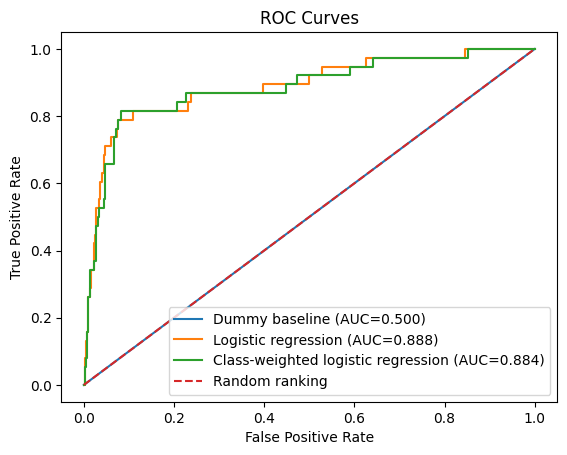

In [2]:
for name, (_, prob) in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], '--', label='Random ranking'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC Curves'); plt.legend(); plt.show()

## Precision-recall curve
Precision-recall analysis is often particularly informative when the positive class is rare.

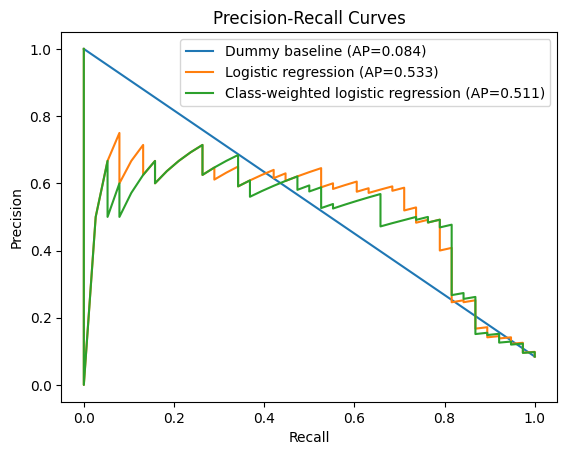

In [3]:
for name, (_, prob) in fitted.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    plt.plot(recall, precision, label=f'{name} (AP={average_precision_score(y_test, prob):.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall Curves'); plt.legend(); plt.show()

## Threshold and confusion matrix
The default threshold is often 0.5, but the best threshold depends on the costs of false positives and false negatives.

                precision    recall  f1-score   support

majority class       0.98      0.91      0.95       412
positive class       0.46      0.82      0.59        38

      accuracy                           0.90       450
     macro avg       0.72      0.86      0.77       450
  weighted avg       0.94      0.90      0.92       450



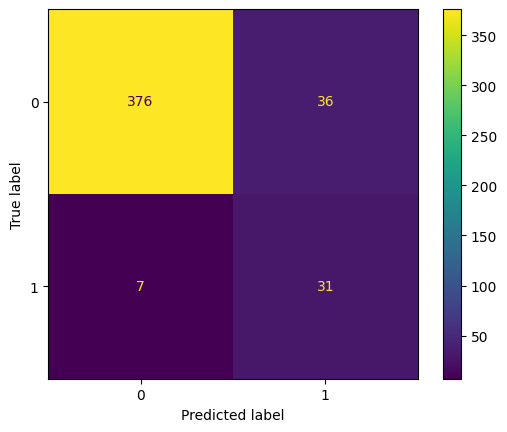

In [4]:
model, probabilities = fitted['Class-weighted logistic regression']
predictions = (probabilities >= 0.5).astype(int)
print(classification_report(y_test, predictions, target_names=['majority class', 'positive class']))
ConfusionMatrixDisplay.from_predictions(y_test, predictions); plt.show()

## Key takeaways
ROC-AUC measures ranking across thresholds. Average precision summarizes precision-recall behavior. For imbalanced data inspect per-class metrics and the confusion matrix. Choose class weights and thresholds using validation data, not the final test set.